Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Accuracy: 0.7990196078431373
Macro Precision: 0.8025252525252525
Macro Recall: 0.7586951447245566
Macro F1: 0.7759790891369839
Weighted Precision: 0.8000557040998217
Weighted Recall: 0.7990196078431373
Weighted F1: 0.7951527660505988
Balanced Accuracy: 0.7586951447245566
Log Loss: 0.5133070789117572


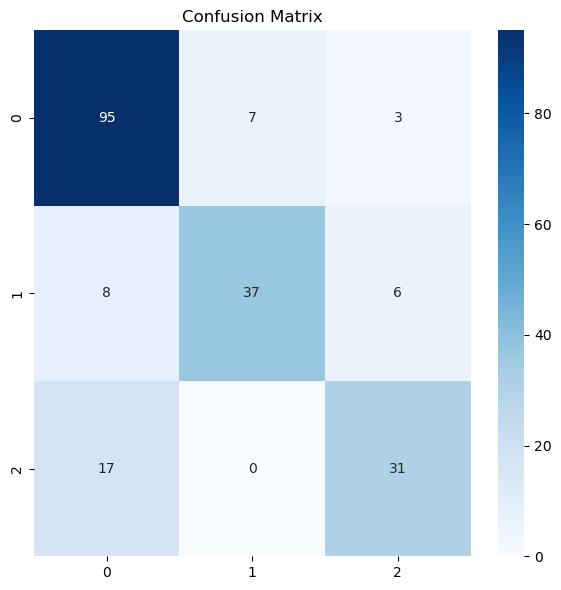

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score,recall_score, f1_score,confusion_matrix,balanced_accuracy_score,log_loss)
from sklearn.ensemble import RandomForestClassifier

df = pd.read_excel("CYP17_ChemoPy.xlsx")
X = df.drop("Activity", axis=1)
y_cat = df["Activity"].astype("category")
y = y_cat.cat.codes.values
class_names = y_cat.cat.categories

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

feature_names = X.columns

# Random Forest + GridSearchCV
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1)

grid.fit(X_train, y_train)

model = grid.best_estimator_

# Evaluation
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro Precision:", precision_score(y_test, y_pred, average="macro"))
print("Macro Recall:", recall_score(y_test, y_pred, average="macro"))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted"))
print("Weighted F1:", f1_score(y_test, y_pred, average="weighted"))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Log Loss:", log_loss(y_test, y_pred_proba))

plt.figure(figsize=(6, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('Confusion_matrix_CSFB.png', format='png', dpi=600)
plt.show()

In [2]:
# get shap values
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test) 

In [3]:
print(np.shape(shap_values))

(204, 633, 3)


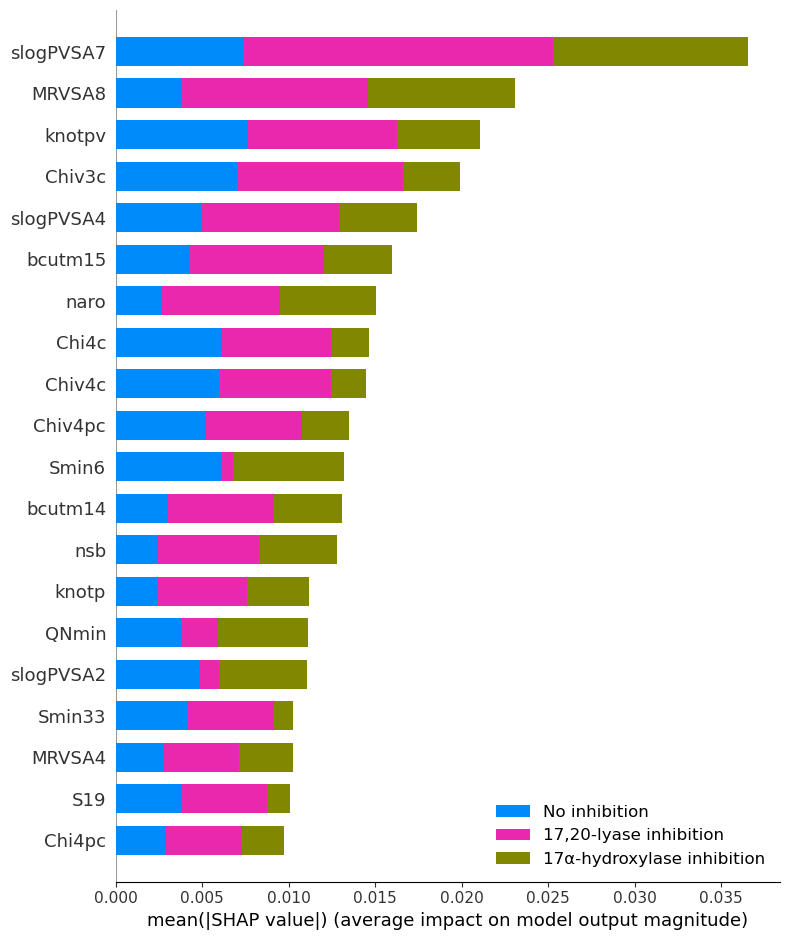

In [7]:
import matplotlib.pyplot as plt
import shap

class_names = ["No inhibition", 
               "17,20-lyase inhibition", 
               "17α-hydroxylase inhibition"]

shap.summary_plot(
    shap_values, 
    X_test, 
    feature_names=feature_names, 
    plot_type="bar", 
    max_display=20, 
    show=False)

ax = plt.gca()  
legend = ax.get_legend()  

if legend is not None:
    for text, new_name in zip(legend.get_texts(), class_names):
        text.set_text(new_name)

plt.savefig("shap_summary_plot_ChemoPy.tiff", dpi=600, bbox_inches='tight')
plt.show()

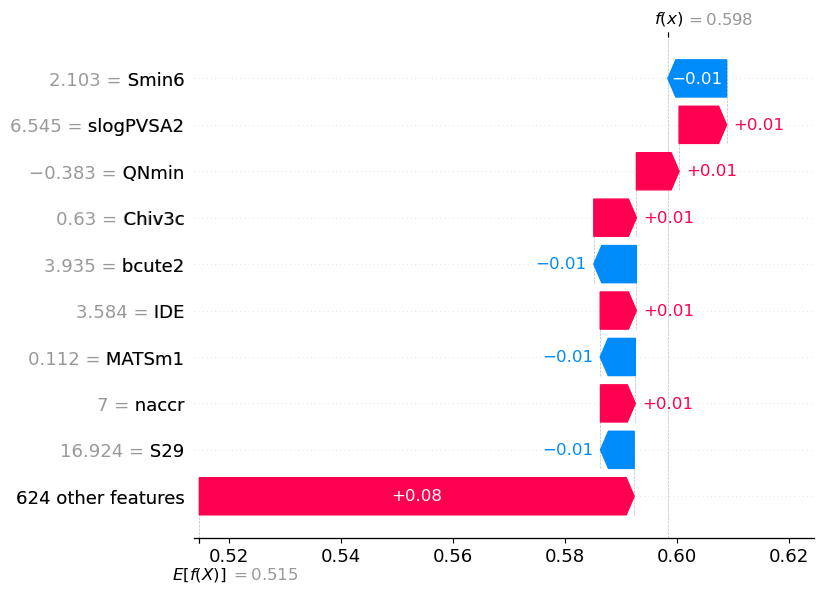

In [11]:
# waterfall plot for first observation
shap.plots.waterfall(shap_values[0, :, 0])

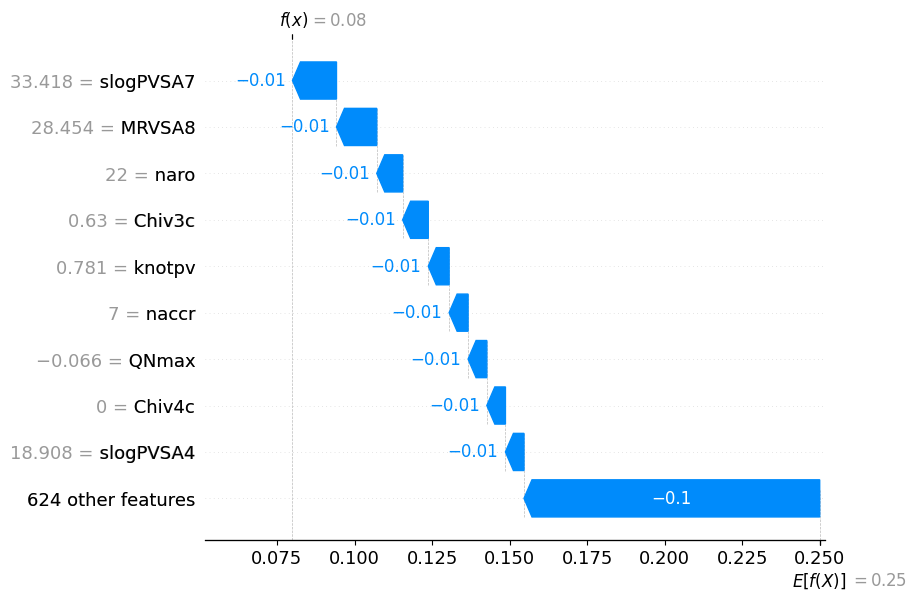

In [13]:
shap.plots.waterfall(shap_values[0, :, 1])

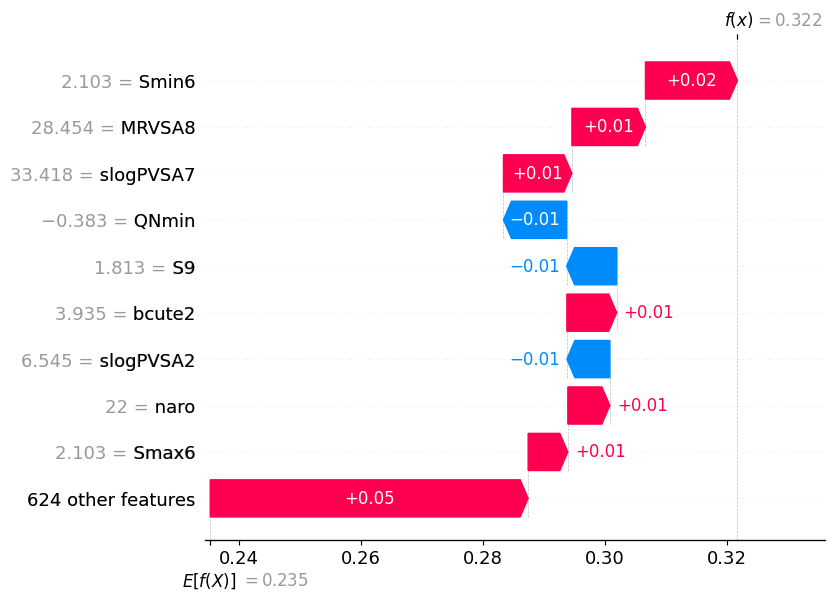

In [15]:
shap.plots.waterfall(shap_values[0, :, 2])

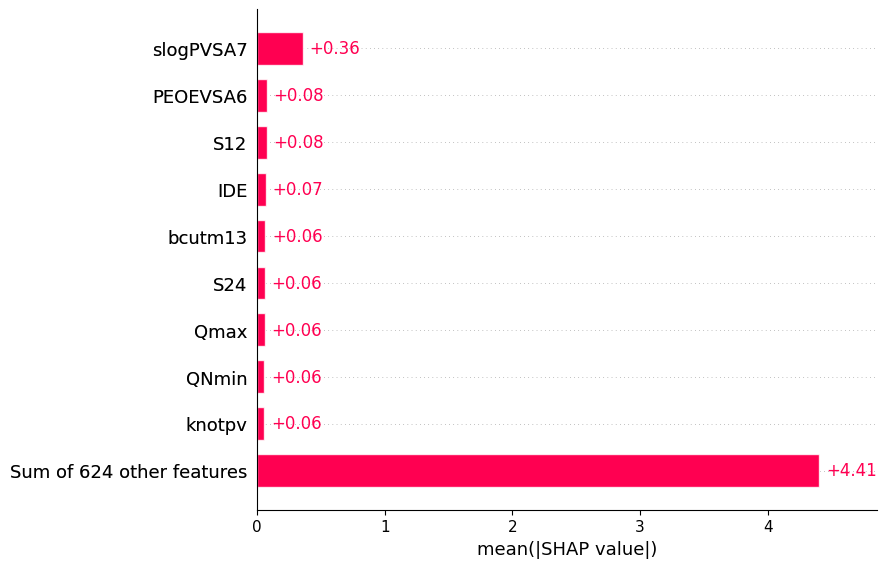

In [93]:
shap.plots.bar(shap_pred)

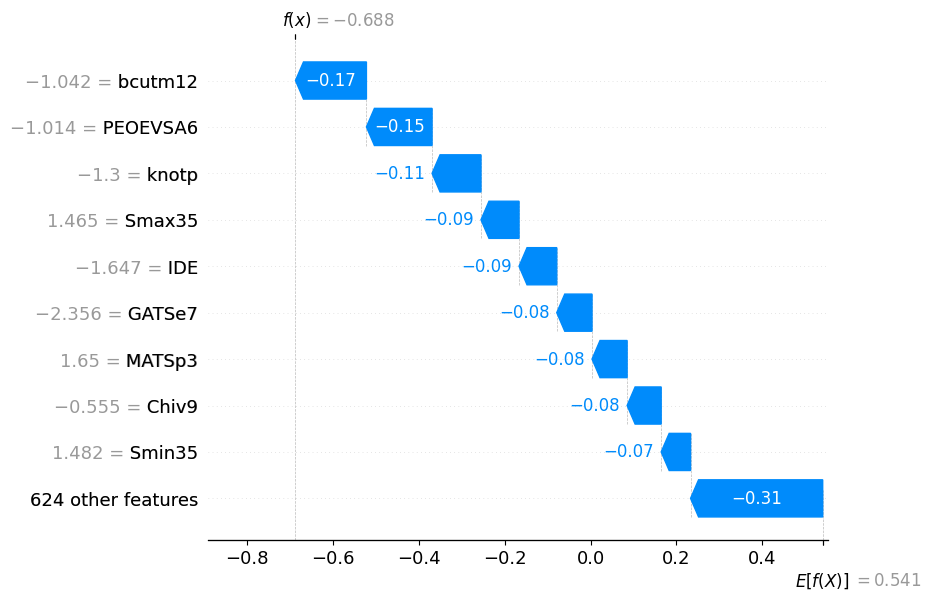

In [63]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values[1][:, 0],
    base_values=explainer.expected_value[0],
    data=X_test[0],
    feature_names=feature_names
))

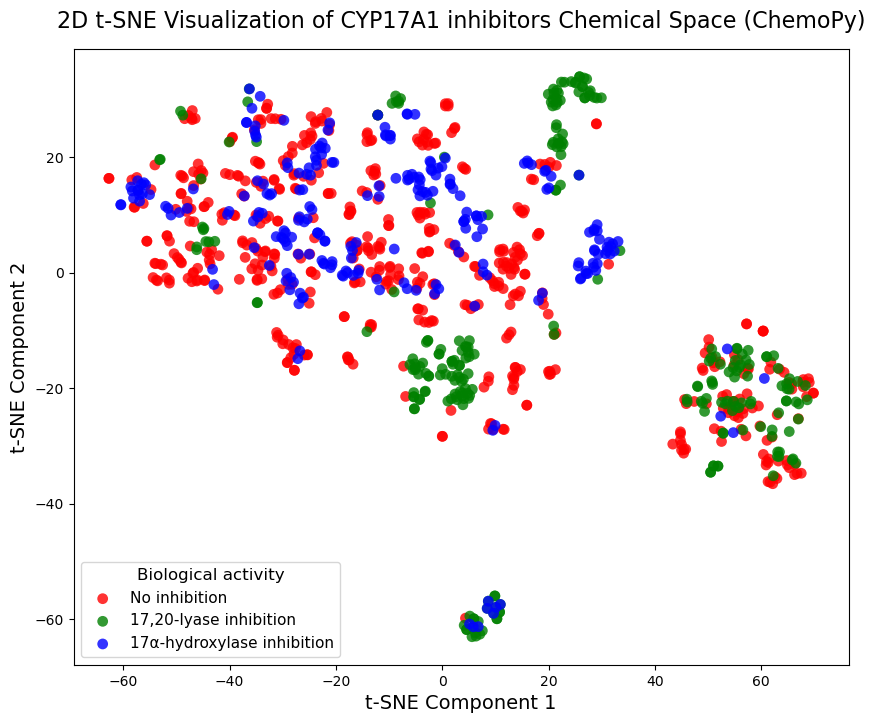

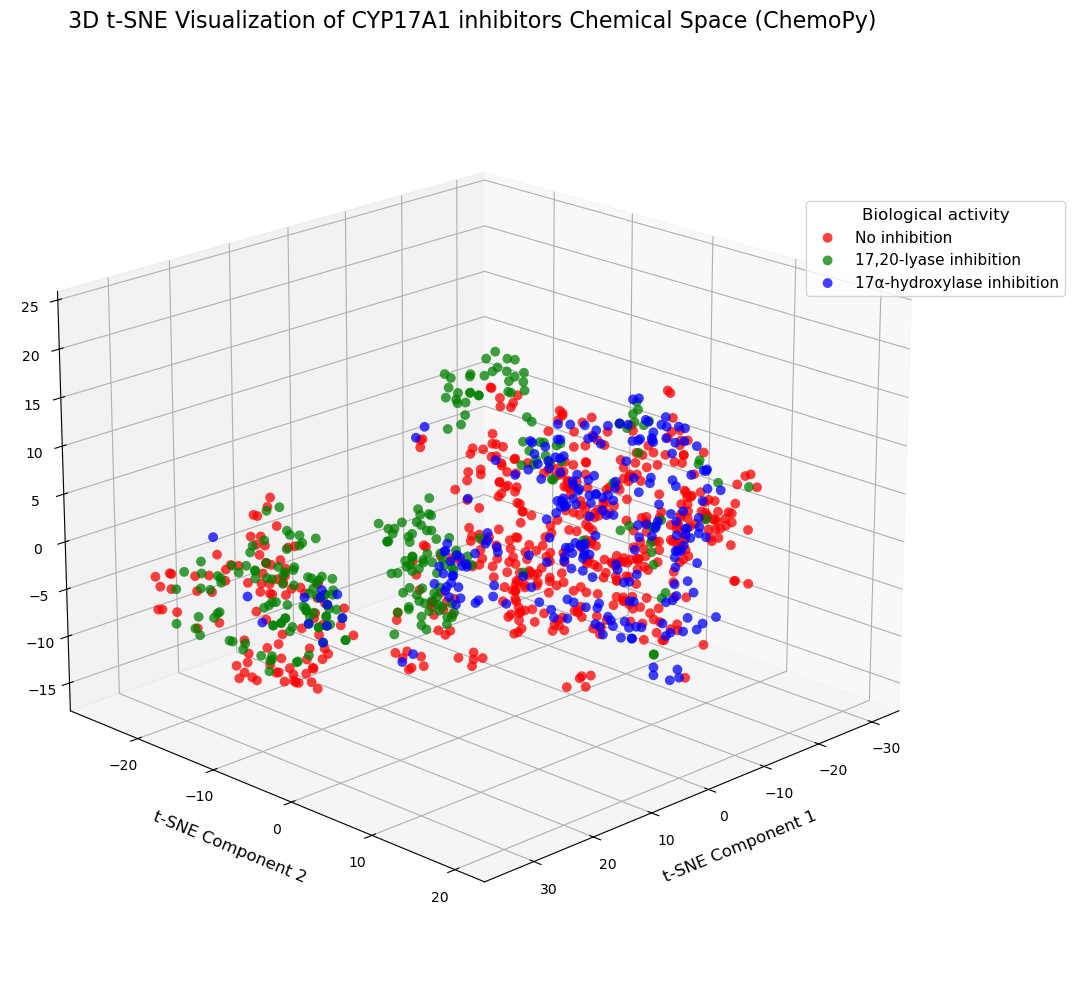

In [13]:
# 2D t-SNE 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_excel('CYP17_ChemoPy.xlsx')
X = df.drop('Activity', axis=1)
y = df['Activity']
X_scaled = StandardScaler().fit_transform(X)
X_pca = PCA(n_components=min(50, X.shape[1]), random_state=42).fit_transform(X_scaled)
class_map = { 0: "No inhibition", 1: "17,20-lyase inhibition", 2: "17α-hydroxylase inhibition"}
y_named = y.map(class_map)
tsne_2d = TSNE(n_components=2, perplexity=30, max_iter=2000, random_state=42)
X_tsne_2d = tsne_2d.fit_transform(X_pca)

colors = {  "No inhibition": "red", "17,20-lyase inhibition": "green", "17α-hydroxylase inhibition": "blue"}

plt.figure(figsize=(10, 8))

for cls in class_map.values():
    mask = (y_named == cls).values 
    
    plt.scatter(
        X_tsne_2d[mask, 0],
        X_tsne_2d[mask, 1],
        s=60,
        alpha=0.8,
        label=cls,
        color=colors[cls],
        edgecolors='none')

plt.title("2D t-SNE Visualization of CYP17A1 inhibitors Chemical Space (ChemoPy)", fontsize=16, pad=15)
plt.xlabel("t-SNE Component 1", fontsize=14)
plt.ylabel("t-SNE Component 2", fontsize=14)
plt.legend(title="Biological activity", fontsize=11, title_fontsize=12, loc="best")
plt.grid(False)

plt.savefig(
    "tsne_2D_chemical_space_CP.png", dpi=600,bbox_inches="tight")
plt.show()

# 3D t-SNE 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_excel('CYP17_ChemoPy.xlsx')

X = df.drop('Activity', axis=1)
y = df['Activity']
X_scaled = StandardScaler().fit_transform(X)
X_pca = PCA(n_components=min(50, X.shape[1]), random_state=42).fit_transform(X_scaled)
y_named = y.map(class_map)

tsne_3d = TSNE(n_components=3, perplexity=30, max_iter=2000, random_state=42)
X_tsne_3d = tsne_3d.fit_transform(X_pca)
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

for cls in class_map.values():
    mask = (y_named == cls).values
    
    ax.scatter(
        X_tsne_3d[mask, 0],
        X_tsne_3d[mask, 1],
        X_tsne_3d[mask, 2],
        s=50,                  
        alpha=0.75,            
        label=cls,
        color=colors[cls],
        edgecolors='none')

ax.set_title("3D t-SNE Visualization of CYP17A1 inhibitors Chemical Space (ChemoPy)", fontsize=16, pad=20)
ax.set_xlabel("t-SNE Component 1", fontsize=12, labelpad=10)
ax.set_ylabel("t-SNE Component 2", fontsize=12, labelpad=10)
ax.set_zlabel("t-SNE Component 3", fontsize=12, labelpad=10)
ax.legend(title="Biological activity", fontsize=11, title_fontsize=12, loc="upper right", bbox_to_anchor=(1.15, 0.85))
ax.view_init(elev=20, azim=45)
plt.tight_layout()
plt.savefig("tsne_3D_chemical_space_CP.png", dpi=600, bbox_inches="tight")
plt.show()

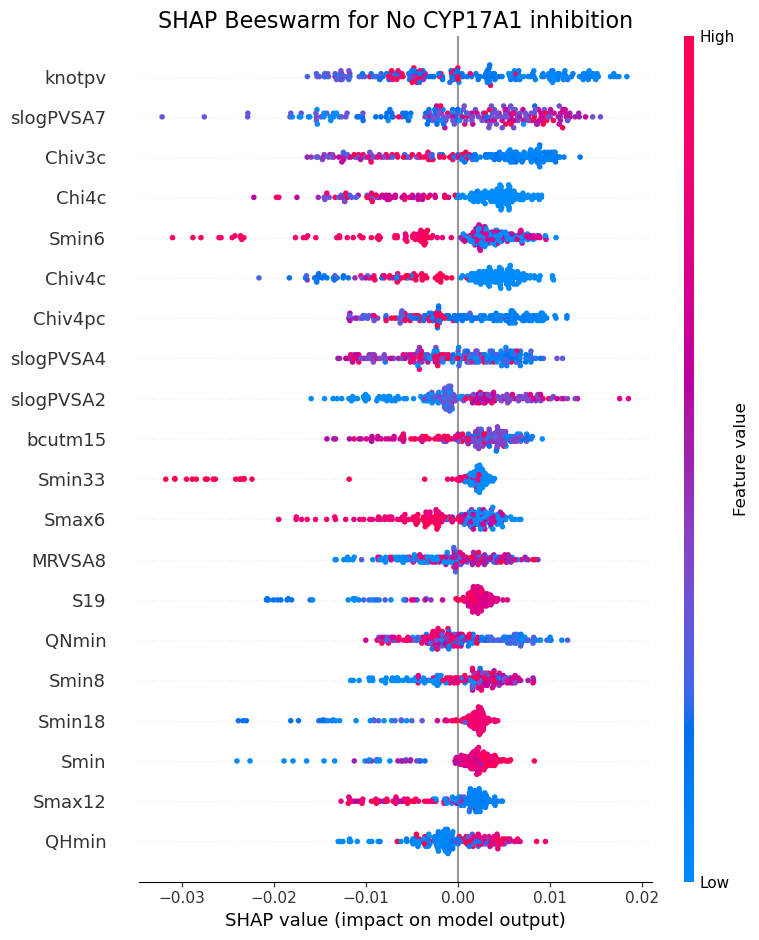

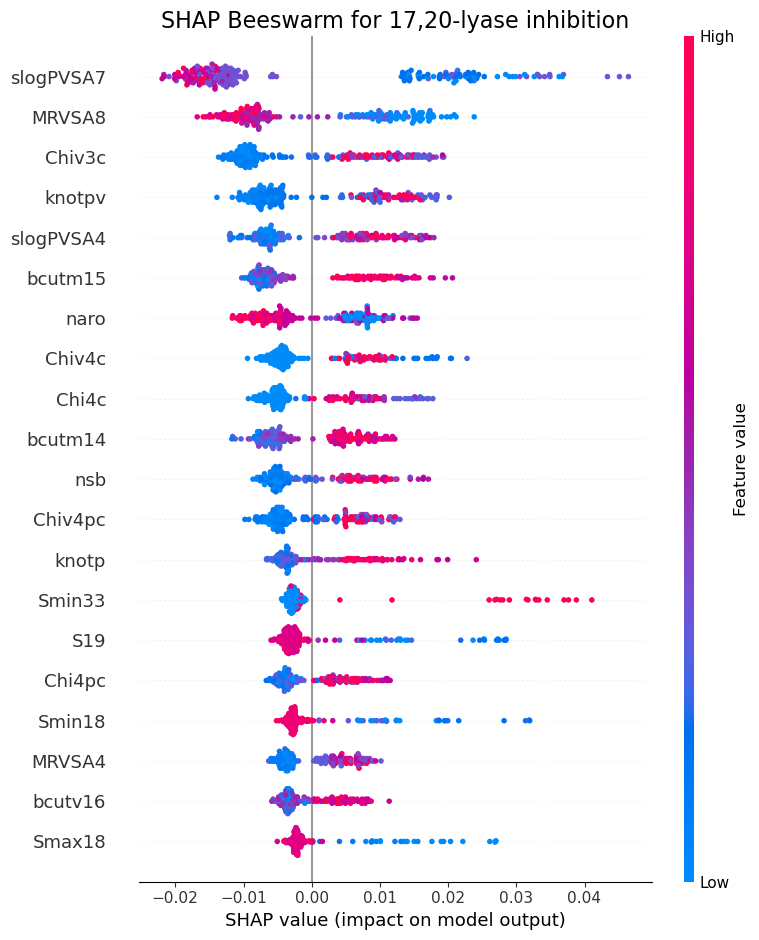

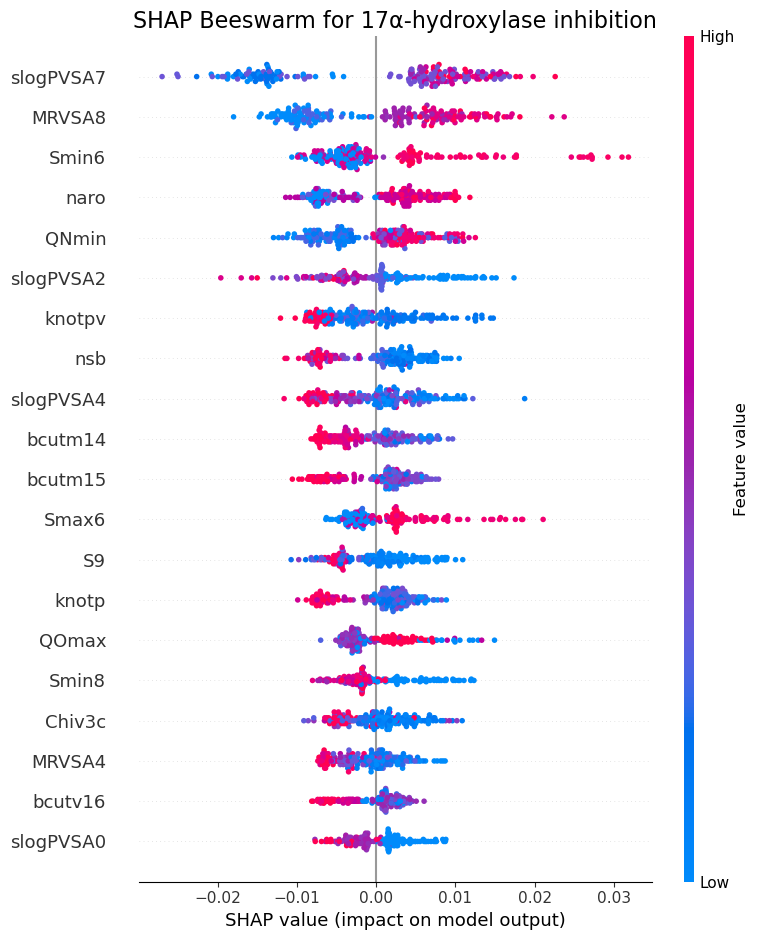

In [14]:
import matplotlib.pyplot as plt
import shap

class_names = {  0: "No CYP17A1 inhibition", 1: "17,20-lyase inhibition", 2: "17α-hydroxylase inhibition"}

for i, cls in class_names.items():
    plt.figure(figsize=(10, 6))

    plt.title(f"SHAP Beeswarm for {cls}", fontsize=16)
    shap.summary_plot(
        shap_values.values[:, :, i],
        X_test,
        feature_names=feature_names,
        show=False)
    plt.savefig(
        f"shap_beeswarm_class_{i}.png",
        dpi=600,
        bbox_inches="tight")

    plt.show()
    plt.close()